# code_040 · Sampling, labels and dataset documentation

**Book:** section 8.4. A dataset-construction laboratory using invented structural-monitoring records. Prerequisites: Python arrays, tables and Chapter 7's information boundaries. Restart and run all cells. Every import, helper and input is here; no ordinary-run files, network, credentials, GPU or private helper are required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_08_GUIDE.md), [run evidence](../CHAPTER_08_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_040).

Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0, CPU. Allow one minute to execute and 30–60 minutes to interpret. These are scoped data-contract experiments rather than exhaustive estimator API studies. Construction identities have no training/test interpretation. The sampling laboratory alone fits two fixed constant predictors and protects an independent final population. No engineering reliability or causal maintenance conclusion follows.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=840;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 840


<a id="frame"></a>
## Inspected buildings are not the population

The finite source frame has 2,000 buildings: 400 older and 1,600 newer. Author-known finding probabilities are .40 and .05. A simple random sample within strata inspects 240 older and 160 newer buildings: old buildings become 60% of inspected cases although only 20% of the frame. Selection probabilities .6/.1 are known by construction and positive in both strata. No unseen covariate/confounding correction is claimed. No row outside the inspection sample is silently labelled negative.

Predeclare two constant probability baselines: the inspected gold-label mean and the known-stratum-share weighted mean. No candidates or tuning; no development set is needed for these two fixed estimators. A separate fresh 2,000-building population with the same stratum shares is sealed until both constants are frozen; final Brier error is mean squared probability error. Population truth is available to the author only because data are simulated.


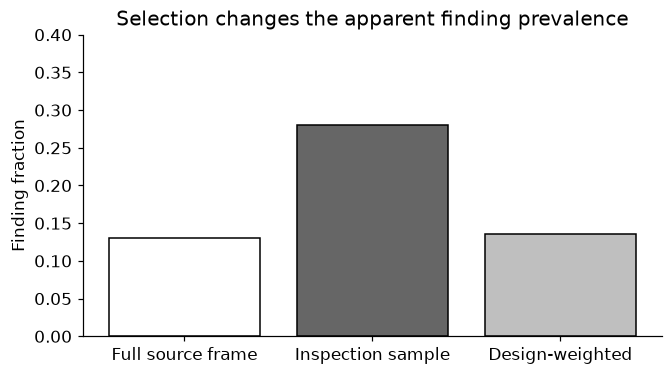

In [2]:
N=2000;old=np.arange(N)<400;truth=rng.random(N)<np.where(old,.40,.05)
selected=np.concatenate([rng.choice(np.flatnonzero(old),240,replace=False),rng.choice(np.flatnonzero(~old),160,replace=False)])
assert len(np.unique(selected))==400 and old[selected].mean()==.6
pi=np.where(old,.6,.1);weights=1/pi[selected];assert np.all(pi>0)
observed=pd.array(np.full(N,np.nan),dtype='Int64');observed[selected]=truth[selected].astype(int)
assert pd.isna(observed).sum()==1600 and pd.notna(observed).sum()==400
naive=float(truth[selected].mean());weighted=float(np.average(truth[selected],weights=weights))
stratified=.2*truth[selected[old[selected]]].mean()+.8*truth[selected[~old[selected]]].mean()
assert np.isclose(weighted,stratified) and np.isclose(weights.sum(),N)
RESULTS.update({'frame_size':N,'inspection_size':400,'older_share_frame':.2,'older_share_sample':.6,'frame_finding_prevalence':float(truth.mean()),'inspection_prevalence':naive,'design_weighted_prevalence':weighted})
fig,ax=plt.subplots(figsize=(6,3.3));ax.bar(['Full source frame','Inspection sample','Design-weighted'],[truth.mean(),naive,weighted],color=['white','.4','.75'],edgecolor='black');ax.set(ylabel='Finding fraction',ylim=(0,.4),title='Selection changes the apparent finding prevalence');plt.show()


<a id="labels"></a>
## Label source is an attribute, not a synonym for truth

In the inspected subset, create an alarm proxy (80% sensitivity, 12% false-positive probability), two imperfect annotators (independent 10%/15% flips conditional on truth), and 10% proxy abstentions. These rates are generator inputs, not learned field accuracy. Reference inspection findings are the teaching target, not a proof of physical failure. Store missing/abstained labels separately from zero. Compare both agreement and author-known correctness; agreement alone cannot establish truth. No weak-label aggregation model is trained.


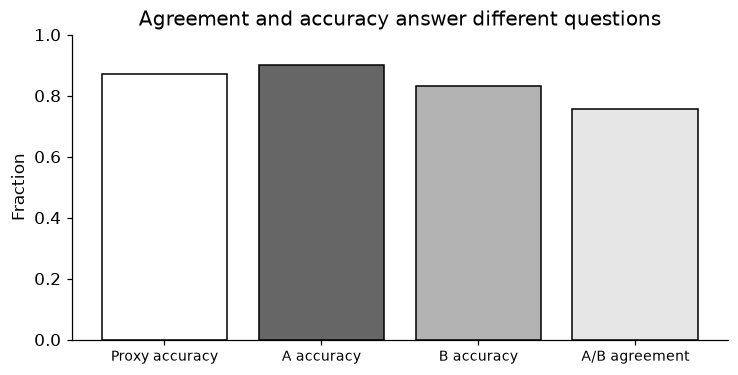

In [3]:
gold=truth[selected].astype(int);weak=np.where(gold==1,rng.random(400)<.8,rng.random(400)<.12).astype(int);abstain=rng.random(400)<.1;weak[abstain]=-1
ann_a=np.logical_xor(gold,rng.random(400)<.1).astype(int);ann_b=np.logical_xor(gold,rng.random(400)<.15).astype(int)
available=weak!=-1;assert (~available).any() and set(weak)<=set([-1,0,1])
accuracy={'Proxy (non-abstain)':float((weak[available]==gold[available]).mean()),'Annotator A':float((ann_a==gold).mean()),'Annotator B':float((ann_b==gold).mean()),'A/B agreement':float((ann_a==ann_b).mean())}
assert all(0<=v<=1 for v in accuracy.values()) and not np.array_equal(ann_a,ann_b)
fig,ax=plt.subplots(figsize=(6.6,3.3));ax.bar(np.arange(4),list(accuracy.values()),color=['white','.4','.7','.9'],edgecolor='black');ax.set(xticks=np.arange(4),xticklabels=['Proxy accuracy','A accuracy','B accuracy','A/B agreement'],ylabel='Fraction',ylim=(0,1),title='Agreement and accuracy answer different questions');ax.tick_params(axis='x',labelsize=9);plt.show()
RESULTS['label_source_checks']=accuracy;RESULTS['proxy_abstentions']=int(abstain.sum())


<a id="final"></a>
## Freeze constants, then assess fresh buildings

The fresh population uses separate random draws and no buildings from the source frame. Neither its labels nor its prevalence choose a baseline or a selection weight. A better result here supports a bounded claim about this known selection mechanism, not the recovery of arbitrary deployment populations from biased labels.


In [4]:
final_old=np.arange(2000)<400;final_y=(rng.random(2000)<np.where(final_old,.40,.05)).astype(float)
final_brier={'inspection_constant':float(np.mean((final_y-naive)**2)),'weighted_constant':float(np.mean((final_y-weighted)**2))}
assert all(np.isfinite(list(final_brier.values()))) and len(final_y)==2000
RESULTS['final_Brier']=final_brier;RESULTS['final_prevalence']=float(final_y.mean())
card={'version':'1.0','unit':'building at fixed baseline date','frame':'2000 generated buildings; older share .2','selection':'240/400 older;160/1600 newer, simple random within strata','target':'reference inspection finding, not physical failure','label_sources':['reference inspection','alarm proxy with abstention','annotator A','annotator B'],'missing_labels':'uninspected and abstained are unknown, not negative','availability':'all source labels resolved before final population is assessed','provenance':'synthetic generator and seed printed in this notebook','limitations':['known positive inclusion probabilities','same-stratum final simulator only','no field validation','no causal conclusion']}
assert {'unit','frame','selection','target','label_sources','missing_labels','availability','provenance','limitations'}<=set(card)
RESULTS['dataset_card']=card;print(json.dumps(card,indent=2));print(final_brier)


{
  "version": "1.0",
  "unit": "building at fixed baseline date",
  "frame": "2000 generated buildings; older share .2",
  "selection": "240/400 older;160/1600 newer, simple random within strata",
  "target": "reference inspection finding, not physical failure",
  "label_sources": [
    "reference inspection",
    "alarm proxy with abstention",
    "annotator A",
    "annotator B"
  ],
  "missing_labels": "uninspected and abstained are unknown, not negative",
  "availability": "all source labels resolved before final population is assessed",
  "provenance": "synthetic generator and seed printed in this notebook",
  "limitations": [
    "known positive inclusion probabilities",
    "same-stratum final simulator only",
    "no field validation",
    "no causal conclusion"
  ]
}
{'inspection_constant': 0.13252, 'weighted_constant': 0.10801500000000001}


<a id="exercises"></a>
## Exercises and hints

1. Give newer buildings zero inspection probability. Explain why inverse weighting cannot recover their risk.
2. Make selection depend on an unrecorded finding precursor within strata. State which weighting assumption fails.
3. Give both annotators the same systematic bias; high agreement may coexist with poor correctness.
4. Write a real dataset card with acquisition permissions, retention, contact, intended uses, limitations and version history. Do not copy the toy selection probabilities into a real survey.

**Hints:** reweighting requires the relevant frame and selection mechanism; estimated weights add uncertainty. A weak alarm, finding, action and failure are different targets. The card is a validated teaching record inspired by [Datasheets for Datasets](https://arxiv.org/abs/1803.09010), not a complete governance or legal assessment. Model/label redesign needs fresh final evidence.


In [5]:
summary={'example_id':'code_040','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['sampling frame and inspection selection', 'known-probability weighting with support', 'weak labels abstention and annotator disagreement', 'dataset card with provenance', 'fixed constant predictors and protected final population'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["sampling frame and inspection selection", "known-probability weighting with support", "weak labels abstention and annotator disagreement", "dataset card with provenance", "fixed constant predictors and protected final population"], "elapsed_seconds": 0.119, "example_id": "code_040", "hardware": "Darwin arm64 CPU", "results": {"dataset_card": {"availability": "all source labels resolved before final population is assessed", "frame": "2000 generated buildings; older share .2", "label_sources": ["reference inspection", "alarm proxy with abstention", "annotator A", "annotator B"], "limitations": ["known positive inclusion probabilities", "same-stratum final simulator only", "no field validation", "no causal conclusion"], "missing_labels": "uninspected and abstained are unknown, not negative", "provenance": "synthetic generator and seed printed in this notebook", "selection": "240/400 older;160/1600 newer, simple random within strata", "tar